# Restaurant Price Optimization — A Product Analytics Experiment

**Question:** can a restaurant raise profit by changing *how prices are presented* on its digital menu, without blanket discounts?

**Approach:** a four-arm randomized experiment (control vs three menu-pricing treatments), evaluated on a pre-defined metric hierarchy with significance testing, segmentation and a staged rollout recommendation.

| | |
|---|---|
| **Primary metric** | Contribution profit per session |
| **Secondary metrics** | Conversion rate, average order value (AOV), revenue per session, units per order |
| **Guardrails** | Conversion must not fall > 2 pp vs control; discount rate |
| **Source data** | UCI Restaurant & Consumer Data (DOI [10.24432/C5DP41](https://doi.org/10.24432/C5DP41), CC BY 4.0) |

> **Data integrity.** Consumer profiles, budgets, occupations and ratings are **genuine** UCI data. Treatment assignment and commercial outcomes (orders, prices, costs) are **simulated**, because no public dataset contains real restaurant A/B-test outcomes. All uplift figures below are therefore **modelled / projected, not achieved in production**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # make `src` importable from notebooks/

import numpy as np
import pandas as pd
from IPython.display import display, Image

from src import config as C
from src import analysis as A
from src import plots as P
from src.simulate import load_uci, build_user_table, simulate_sessions

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 160)

## 1. The genuine source data (UCI)

Three tables are used: consumer profiles (budget, occupation), restaurant attributes, and 1,161 ratings (0–2 scale). Each consumer's **mean overall rating** becomes their baseline purchase propensity, and consumers who rated more restaurants appear in proportionally more sessions.

In [2]:
uci = load_uci()
users = build_user_table(uci["ratings"], uci["profiles"])
print(f"Ratings: {len(uci['ratings']):,} | Consumers: {len(uci['profiles'])} | Restaurants: {len(uci['restaurants'])}")
display(users.head())
display(pd.crosstab(users["customer_segment"], users["budget"], margins=True))

Ratings: 1,161 | Consumers: 138 | Restaurants: 130


,user_id,activity,budget,mean_rating,n_ratings,customer_segment
0,U1001,student,Medium,1.111,9,Students
1,U1002,student,Low,1.400,10,Students
2,U1003,student,Low,1.615,13,Students
3,U1004,professional,Medium,1.875,8,Professionals
4,U1005,student,Medium,1.333,9,Students


budget,High,Low,Medium,All
customer_segment,,,,
Other,1,0,8,9
Professionals,0,0,15,15
Students,4,35,74,113
Working Class,0,0,1,1
All,5,35,98,138


In [3]:
# The restaurant chosen as the experiment's setting
r = uci["restaurants"].set_index("placeID").loc[C.SELECTED_PLACE_ID, ["name", "city", "price", "alcohol", "Rambience"]]
place_ratings = uci["ratings"][uci["ratings"]["placeID"] == C.SELECTED_PLACE_ID]
print(r.to_string())
print(f"Observed mean rating: {place_ratings['rating'].mean():.2f} / 2 from {len(place_ratings)} ratings")

name         Restaurant Bar Hacienda los Martinez
city                              San Luis Potosi
price                                      medium
alcohol                                 Wine-Beer
Rambience                                familiar
Observed mean rating: 1.67 / 2 from 9 ratings


## 2. Experiment design

| Variant | What the customer sees | Behavioural hypothesis |
|---|---|---|
| **A – Control** | Rounded prices, standard descriptions | Causal benchmark |
| **B – Charm Pricing** | Prices ending in 9 (₹299) | Lower *perceived* price → higher conversion, mainly for budget-sensitive users |
| **C – Premium Framing** | Premium descriptions, higher reference value | Higher willingness to pay, at some conversion cost |
| **D – Anchor + Combo** | An expensive anchor item next to a framed value combo | The anchor makes the combo look like a deal → more conversion **and** bigger baskets |

**Hypotheses.** H0(conversion): conversion is independent of variant. H0(AOV): mean order value is equal across variants. **Decision rule:** recommend the variant with the highest profit per session, provided conversion does not fall by more than 2 pp and the result is statistically significant.

The simulation's treatment assumptions are kept explicit in `src/config.py`:

In [4]:
design = pd.DataFrame(C.VARIANTS).T
design.insert(0, "experience", pd.Series(C.VARIANT_DESCRIPTIONS))
design

,experience,price_mult,conv_effect,units_effect,discount
A - Control,Current menu; rounded prices and standard item...,1.000,0.000,0.000,0.000
B - Charm Pricing,Prices ending in 9 (e.g. Rs 299) to reduce per...,0.997,0.022,0.020,0.003
C - Premium Framing,Premium descriptions and higher reference-qual...,1.055,-0.014,-0.010,0.000
D - Anchor + Combo,High-priced anchor item next to a prominently ...,1.025,0.055,0.120,0.018


In [5]:
econ = pd.Series({
    "Base item price (Rs)": C.BASE_ITEM_PRICE,
    "Food cost (COGS) ratio": C.COGS_RATIO,
    "Packaging cost per order (Rs)": C.PACKAGING_COST_PER_ORDER,
    "Payment fee rate": C.PAYMENT_FEE_RATE,
    "Monthly sessions for scaling": C.MONTHLY_SESSIONS,
}, name="assumption")
econ.to_frame()

,assumption
Base item price (Rs),340.000
Food cost (COGS) ratio,0.340
Packaging cost per order (Rs),18.000
Payment fee rate,0.018
Monthly sessions for scaling,"50,000.000"


## 3. How the sessions are simulated

For each of 8,000 sessions (2,000 per arm, randomly ordered), `src/simulate.py`:

1. **Samples a real UCI consumer**, weighted by how many restaurants they rated.
2. Draws a **date** (Jan–Mar 2026) and **channel** (delivery / dine-in / takeaway).
3. Computes a **conversion probability**: intercept + 0.148 × user's mean rating + budget, segment, channel and weekend effects + the variant's treatment effect (+ heterogeneous effects: charm pricing helps low-budget users, premium framing helps high-budget users, combos resonate with students) + small noise.
4. Draws **converted ~ Bernoulli(p)**.
5. If converted, draws **items ~ max(1, Poisson(1.7 × (1 + units effect)))** and a **price per item** = ₹340 × budget factor × variant price multiplier × noise.
6. Applies the variant **discount**, then unit economics: *contribution profit = net revenue − 34% food cost − ₹18 packaging − 1.8% payment fee*.

**Reproducibility check.** The published dataset (`data/processed/restaurant_pricing_experiment_dataset.csv`) is the one all results are based on. Re-running the simulator with a fresh seed produces a statistically equivalent dataset — same model probabilities, same ranking of variants — though individual random draws differ:

In [6]:
published = A.load_experiment()
regenerated = simulate_sessions(seed=C.SEED)

cmp = pd.concat({
    "published": published.groupby("variant").agg(model_p=("conversion_probability_model", "mean"),
                                                   conversion=("converted", "mean"),
                                                   profit_per_session=("contribution_profit_inr", "mean")),
    "regenerated": regenerated.groupby("variant").agg(model_p=("conversion_probability_model", "mean"),
                                                      conversion=("converted", "mean"),
                                                      profit_per_session=("contribution_profit_inr", "mean")),
}, axis=1)
cmp

published                               regenerated                              
                      model_p conversion profit_per_session     model_p conversion profit_per_session
variant                                                                                              
A - Control             0.474      0.498            192.636       0.474      0.475            180.027
B - Charm Pricing       0.502      0.531            204.976       0.502      0.506            197.881
C - Premium Framing     0.458      0.454            181.167       0.462      0.447            176.144
D - Anchor + Combo      0.542      0.538            225.827       0.542      0.544            230.643

## 4. Data quality and experiment validity

Before reading any result: check the data is clean, the split is balanced (**sample ratio mismatch**), and the test had enough sessions to detect a meaningful change (**minimum detectable effect**).

In [7]:
df = published
print(f"Rows: {len(df):,} | Columns: {df.shape[1]} | Missing values: {df.isna().sum().sum()} | Duplicate sessions: {df['session_id'].duplicated().sum()}")
print(f"Unique UCI users: {df['user_id'].nunique()} | Date range: {df['session_date'].min()} to {df['session_date'].max()}")

srm = A.sample_ratio_mismatch(df)
print(f"\nSRM check: {srm['counts']}  chi2={srm['chi2']:.2f}, p={srm['p_value']:.3f} -> {'SRM DETECTED' if srm['srm_detected'] else 'allocation OK'}")

base_conv = df.loc[df['variant'] == C.CONTROL, 'converted'].mean()
mde = A.minimum_detectable_effect(C.SESSIONS_PER_VARIANT, base_conv)
print(f"Minimum detectable conversion effect (alpha=0.05, power=80%, 2,000/arm): {mde*100:.1f} pp")

# Sanity check: profit is internally consistent with the cost model
chk = (df['net_revenue_inr'] - df['variable_cost_inr'] - df['contribution_profit_inr']).abs().max()
print(f"Max profit reconciliation error: Rs {chk:.2f}")

Rows: 8,000 | Columns: 18 | Missing values: 0 | Duplicate sessions: 0
Unique UCI users: 138 | Date range: 2026-01-01 to 2026-03-25

SRM check: {'A - Control': 2000, 'B - Charm Pricing': 2000, 'C - Premium Framing': 2000, 'D - Anchor + Combo': 2000}  chi2=0.00, p=1.000 -> allocation OK
Minimum detectable conversion effect (alpha=0.05, power=80%, 2,000/arm): 4.4 pp
Max profit reconciliation error: Rs 0.01


> **Note on power.** With 2,000 sessions per arm the test can reliably detect a conversion change of about 4.4 pp. Anchor + Combo's lift (+4.0 pp) sits right at that threshold, so its conversion result is significant here but would need a larger live test to confirm with confidence.

## 5. Results by variant

In [8]:
summary = A.variant_summary(df)
cols = ["sessions", "orders", "conversion", "aov_inr", "units_per_order", "discount_rate",
        "revenue_per_session_inr", "profit_per_session_inr", "conv_lift", "rps_lift", "profit_lift"]
summary[cols]

,sessions,orders,conversion,aov_inr,units_per_order,discount_rate,revenue_per_session_inr,profit_per_session_inr,conv_lift,rps_lift,profit_lift
variant,,,,,,,,,,,
A - Control,2000,996,0.498,630.560,1.887,0.000,314.019,192.636,0.000,0.000,0.000
B - Charm Pricing,2000,1062,0.531,629.313,1.908,0.003,334.165,204.976,0.066,0.064,0.064
C - Premium Framing,2000,908,0.454,649.606,1.841,0.000,294.921,181.167,-0.088,-0.061,-0.060
D - Anchor + Combo,2000,1076,0.538,681.857,2.014,0.018,366.839,225.827,0.080,0.168,0.172


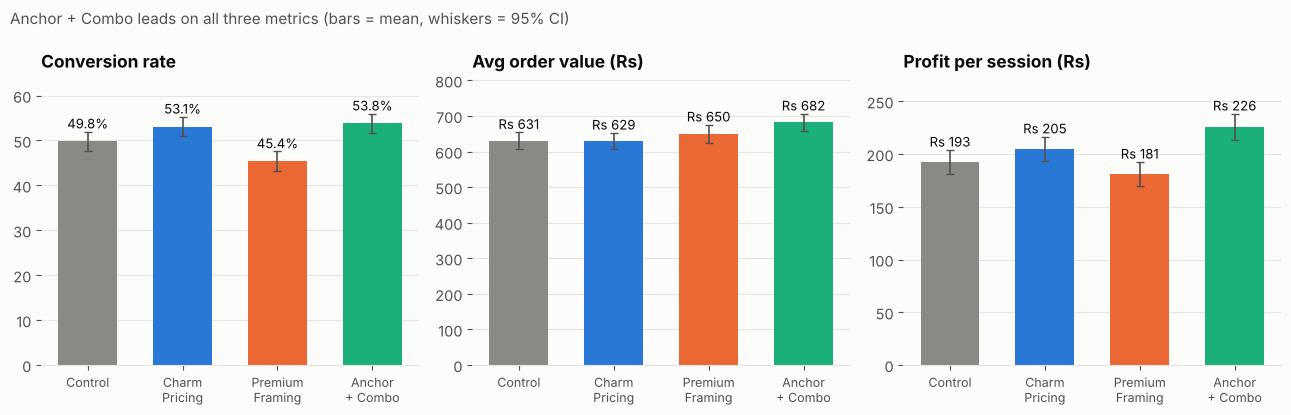

In [9]:
P.kpi_bars(df);

**Reading the table.** Anchor + Combo wins on profit per session (₹225.83 vs ₹192.64, **+17.2%**) because it moves *both* levers: more people order (+8% conversion) and each order is bigger (+8% AOV, driven by ~2.0 vs 1.9 items). Premium Framing shows the expected trade-off: higher AOV but lower conversion, so profit per session falls. Charm Pricing lifts conversion but barely changes basket size.

## 6. Statistical validation

### 6a. Conversion — chi-square test of independence, then pairwise tests vs control

In [10]:
chi = A.chi_square_conversion(df)
print(f"{chi['test']}: chi2 = {chi['statistic']:.2f}, dof = {chi['dof']}, p = {chi['p_value']:.3g}")
A.conversion_vs_control(df)

Chi-square: conversion vs variant: chi2 = 35.32, dof = 3, p = 1.04e-07


,variant,diff_pp,z,p_value,p_holm,significant
0,B - Charm Pricing,3.300,2.088,0.037,0.037,True
1,C - Premium Framing,-4.400,-2.786,0.005,0.016,True
2,D - Anchor + Combo,4.000,2.531,0.011,0.023,True


The omnibus test rejects H0: conversion depends on variant. Pairwise z-tests (Holm-adjusted for three comparisons) show all three treatments differ from control on conversion — B and D upward, C downward.

### 6b. Order value — one-way ANOVA, then Tukey HSD

ANOVA only says *some* variant differs; Tukey HSD tests every pair while controlling the family-wise error rate.

In [11]:
anova = A.anova_aov(df)
print(f"{anova['test']}: F = {anova['statistic']:.2f}, p = {anova['p_value']:.4f}")
A.tukey_aov(df)

One-way ANOVA: order value: F = 4.02, p = 0.0072


,group1,group2,mean_diff_inr,p_adj,lower,upper,significant
0,A - Control,B - Charm Pricing,-1.247,1.000,-46.332,43.838,False
1,A - Control,C - Premium Framing,19.045,0.724,-27.853,65.944,False
2,A - Control,D - Anchor + Combo,51.297,0.018,6.355,96.240,True
3,B - Charm Pricing,C - Premium Framing,20.293,0.672,-25.906,66.491,False
4,B - Charm Pricing,D - Anchor + Combo,52.544,0.012,8.333,96.756,True
5,C - Premium Framing,D - Anchor + Combo,32.252,0.274,-13.808,78.312,False


Anchor + Combo's order value is significantly higher than Control and Charm Pricing. It is **not** significantly different from Premium Framing (p ≈ 0.27) — premium framing also raises order value, it just loses too many customers along the way.

### 6c. Profit per session — the primary metric

Welch's t-test (unequal variances) per treatment vs control, Holm-adjusted, plus a 5,000-sample bootstrap as a distribution-free cross-check (profit per session is zero-inflated because ~half of sessions don't order).

,variant,diff_inr,ci_low,ci_high,t,p_value,p_holm,significant
0,B - Charm Pricing,12.340,-3.987,28.667,1.481,0.139,0.277,False
1,C - Premium Framing,-11.469,-27.720,4.782,-1.383,0.167,0.277,False
2,D - Anchor + Combo,33.191,16.227,50.154,3.835,0.000,0.000,True


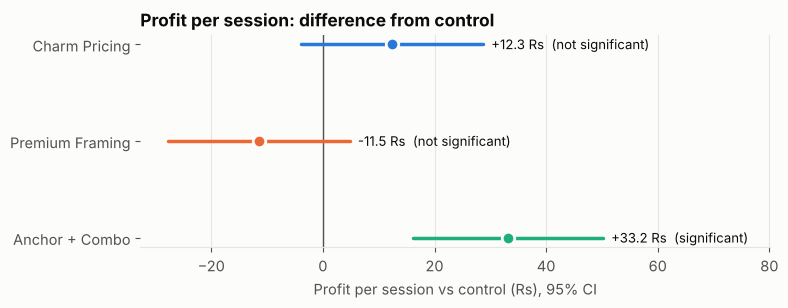

In [12]:
profit_tests = A.profit_vs_control(df)
display(profit_tests)
P.lift_vs_control(profit_tests);

Only **Anchor + Combo** is significantly more profitable than control (+₹33.2 per session, 95% CI ₹16–50, Holm p < 0.001). Charm Pricing's conversion gain does **not** translate into a significant profit gain — a good illustration of why the primary metric matters more than conversion alone.

## 7. Customer segmentation

In [13]:
seg = A.segment_summary(df)
seg[["sessions", "conversion", "aov_inr", "profit_per_session_inr"]]

sessions  conversion   aov_inr  profit_per_session_inr
customer_segment variant                                                                    
Other            A - Control               105       0.410   611.352                 153.362
                 B - Charm Pricing         121       0.455   588.225                 163.473
                 C - Premium Framing       121       0.529   665.771                 216.555
                 D - Anchor + Combo        100       0.510   708.207                 222.701
Professionals    A - Control               214       0.528   620.482                 200.838
                 B - Charm Pricing         206       0.515   621.289                 195.980
                 C - Premium Framing       226       0.456   760.468                 214.304
                 D - Anchor + Combo        197       0.599   694.060                 256.118
Students         A - Control              1675       0.500   633.753                 194.319
                 B - Charm Pricing        1661       0.538   631.224                 208.427
                 C - Premium Framing      1645       0.448   633.196                 174.063
                 D - Anchor + Combo       1698       0.532   677.611                 222.021
Working Class    A - Control                 6       0.500   394.760                 117.717
                 B - Charm Pricing          12       0.583   829.630                 300.197
                 C - Premium Framing         8       0.500   559.798                 170.695
                 D - Anchor + Combo          5       0.600 1,033.577                 387.332

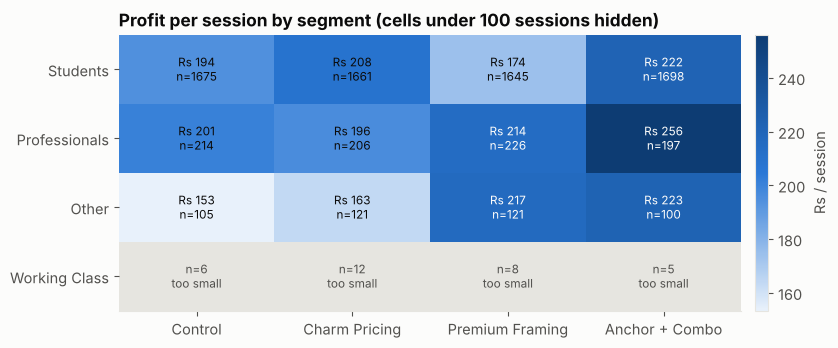

In [14]:
P.segment_heatmap(seg);

- **Students** (≈ 83% of sessions): Anchor + Combo and Charm Pricing both beat control; Premium Framing hurts.
- **Professionals**: Anchor + Combo is strongest (₹256/session); Premium Framing beats control here, consistent with higher willingness to pay.
- **Working Class** has only 5–12 sessions per variant — **too small to draw any conclusion**, so it is excluded from interpretation.

Segment results are exploratory (not pre-registered and not multiplicity-corrected). They suggest **targeted** pricing is worth testing next, not that it is proven.

## 8. Decision and business impact

Recommended variant: D - Anchor + Combo
Profit per session: Rs 225.83 vs Rs 192.64 (control)
Modelled incremental contribution profit @ 50,000 sessions/month:
  Point estimate : Rs 1,659,531 / month  (Rs 19,914,369 / year)
  95% bootstrap  : Rs 823,971 to Rs 2,509,002 / month


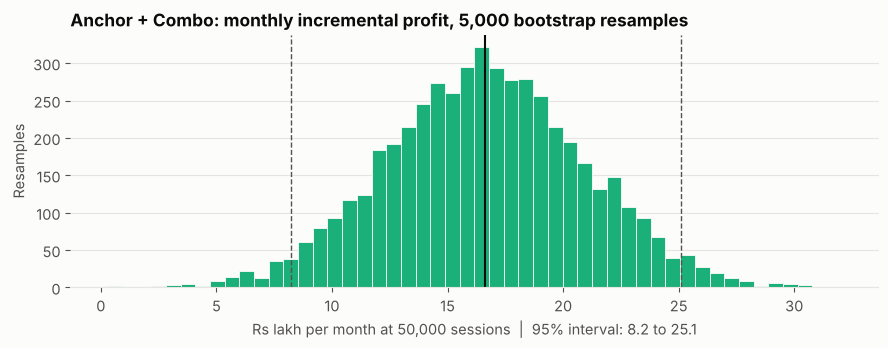

In [15]:
winner = A.pick_winner(summary)
boot = A.bootstrap_profit_lift(df, winner)
impact = A.monthly_impact(summary, winner, boot=boot)

print(f"Recommended variant: {winner}")
print(f"Profit per session: Rs {summary.loc[winner, 'profit_per_session_inr']:.2f} vs Rs {summary.loc[C.CONTROL, 'profit_per_session_inr']:.2f} (control)")
print(f"Modelled incremental contribution profit @ {C.MONTHLY_SESSIONS:,} sessions/month:")
print(f"  Point estimate : Rs {impact['monthly_incremental_profit']:,.0f} / month  (Rs {impact['annual_incremental_profit']:,.0f} / year)")
print(f"  95% bootstrap  : Rs {impact['monthly_ci_low']:,.0f} to Rs {impact['monthly_ci_high']:,.0f} / month")
P.bootstrap_hist(boot);

### Recommendation: advance **D – Anchor + Combo** to a controlled live pilot

1. **Stage 1** — 10% of eligible traffic for two weeks, with **user-level** (not session-level) assignment so returning customers always see the same menu.
2. **Stage 2** — scale to 50% only if profit per session stays positive, conversion does not fall by more than 2 pp, and cancellation / refund / complaint guardrails remain stable.
3. **Stage 3** — full rollout with a small permanent holdout to keep measuring the effect.
4. **Next test** — segment-targeted pricing: charm pricing for low-budget users, premium framing for high-budget users.

## 9. Limitations

- **Simulated outcomes.** The treatment effects are model inputs, so this project demonstrates the experimentation and analysis workflow — it does not prove that anchoring works. That is what the live pilot is for.
- **Session-level randomization.** Every UCI user appears in all four arms (138 users across 8,000 sessions). In production this would contaminate results; the rollout plan uses user-level assignment to fix it.
- **Geography / currency.** UCI consumers are from Mexico; prices and costs are illustrative INR inputs. The real data shapes *relative* purchase propensity, not price levels.
- **Not modelled:** novelty effects, repeat-purchase behaviour, competitor reactions, kitchen capacity, and long-run discount dependence from the combo (1.8% discount rate).